<a href="https://colab.research.google.com/github/hazmi16194/ml-zoomcamp-2024-sales-forecasting/blob/main/notebooks/ml_zoomcamp_2024_sales_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import json
import zipfile
from google.colab import userdata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore")

In [3]:
# 1. Fetch credentials from Colab Secrets
try:
    username = userdata.get('KAGGLE_USERNAME')
    key = userdata.get('KAGGLE_KEY')
    print("🔑 Loaded Kaggle credentials from Secrets.")
except Exception as e:
    print("❌ Error fetching Secrets:", e)

# 2. Write credentials to ~/.kaggle/kaggle.json
kaggle_dir = os.path.expanduser('~/.kaggle')
os.makedirs(kaggle_dir, exist_ok=True)

kaggle_json_path = os.path.join(kaggle_dir, 'kaggle.json')
with open(kaggle_json_path, 'w') as f:
    json.dump({'username': username, 'key': key}, f)

# Set strict file permissions required by Kaggle CLI
os.chmod(kaggle_json_path, 0o600)

# Set environment variables for subshells
os.environ['KAGGLE_USERNAME'] = username
os.environ['KAGGLE_KEY'] = key

print("✅ Credentials file ~/.kaggle/kaggle.json written successfully.")

# 3. Create destination directory and download
!mkdir -p data/raw
COMPETITION = "ml-zoomcamp-2024-competition"

print(f"\nDownloading dataset for '{COMPETITION}'...")
!kaggle competitions download -c {COMPETITION} -p data/raw

# 4. Extract downloaded ZIP files
for file in os.listdir('data/raw'):
    if file.endswith('.zip'):
        zip_path = os.path.join('data/raw', file)
        print(f"Extracting {file}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall('data/raw')
        os.remove(zip_path)

print("\n🎉 Files successfully placed in 'data/raw':")
print(os.listdir('data/raw'))

🔑 Loaded Kaggle credentials from Secrets.
✅ Credentials file ~/.kaggle/kaggle.json written successfully.

100% 216M/216M [00:11<00:00, 19.8MB/s]

Extracting ml-zoomcamp-2024-competition.zip...

🎉 Files successfully placed in 'data/raw':
['actual_matrix.csv', 'price_history.csv', 'sample_submission.csv', 'catalog.csv', 'test.csv', 'stores.csv', 'markdowns.csv', 'discounts_history.csv', 'sales.csv', 'online.csv']


In [4]:
# Load sales data
df_raw = pd.read_csv('data/raw/sales.csv')
df_raw.columns = [c.lower().strip() for c in df_raw.columns]
df_raw['date'] = pd.to_datetime(df_raw['date'])

print("=== 1. MISSING VALUES CHECK ===")
print(df_raw.isnull().sum())

print("\n=== 2. DATA TYPES & SUMMARY ===")
print(df_raw[['quantity', 'sum_total', 'price_base']].describe())

print("\n=== 3. CHECK FOR DATE GAPS IN TIMELINE ===")
# Daily timeline check
df_daily = df_raw.groupby('date')['quantity'].sum().reset_index()
df_daily = df_daily.sort_values('date').reset_index(drop=True)

full_date_range = pd.date_range(start=df_daily['date'].min(), end=df_daily['date'].max(), freq='D')
missing_dates = full_date_range.difference(df_daily['date'])

print(f"Start Date: {df_daily['date'].min().strftime('%Y-%m-%d')}")
print(f"End Date:   {df_daily['date'].max().strftime('%Y-%m-%d')}")
print(f"Expected Days: {len(full_date_range)} | Actual Unique Days: {len(df_daily)}")
print(f"Missing Days in Sequence: {len(missing_dates)}")

if len(missing_dates) > 0:
    print("\n⚠️ Missing Dates Found! Reindexing to fill missing days with 0 quantity...")
    df_daily = df_daily.set_index('date').reindex(full_date_range, fill_value=0).rename_axis('date').reset_index()
else:
    print("\n✅ Continuous daily timeline confirmed (No date gaps)!")

=== 1. MISSING VALUES CHECK ===
unnamed: 0    0
date          0
item_id       0
quantity      0
price_base    0
sum_total     0
store_id      0
dtype: int64

=== 2. DATA TYPES & SUMMARY ===
           quantity     sum_total    price_base
count  7.432685e+06  7.432685e+06  7.432685e+06
mean   5.642398e+00  7.612796e+02  2.075824e+02
std    2.740466e+01  4.789478e+03  3.372886e+02
min   -5.000000e+02 -2.041080e+04 -2.167667e+04
25%    1.000000e+00  1.279000e+02  6.000000e+01
50%    2.000000e+00  2.596000e+02  1.099000e+02
75%    4.672000e+00  5.990000e+02  1.999000e+02
max    4.952000e+03  6.865242e+05  2.899990e+04

=== 3. CHECK FOR DATE GAPS IN TIMELINE ===
Start Date: 2022-08-28
End Date:   2024-09-26
Expected Days: 761 | Actual Unique Days: 761
Missing Days in Sequence: 0

✅ Continuous daily timeline confirmed (No date gaps)!


✅ df_featured successfully defined! Dataset shape: (733, 14)

=== FEATURE DISTRIBUTION SUMMARY ===


,Feature,Mean,Std Dev,Median (Q2),IQR,Min,Max,Skewness,Zero Count
0,quantity,55607.01,19500.65,45419.88,32264.36,19245.05,154066.88,0.88,0
1,day_of_week,3.00,2.00,3.00,4.00,0.00,6.00,0.00,105
2,day_of_month,15.77,8.81,16.00,15.00,1.00,31.00,0.00,0
3,month,6.53,3.45,7.00,6.00,1.00,12.00,-0.01,0
4,quarter,2.51,1.12,3.00,2.00,1.00,4.00,-0.01,0
5,is_weekend,0.29,0.45,0.00,1.00,0.00,1.00,0.95,524
6,lag_1,55551.25,19483.83,45343.29,32246.64,19245.05,154066.88,0.89,0
7,lag_7,55213.54,19341.70,44831.15,31650.13,19245.05,154066.88,0.92,0
8,lag_14,54814.86,19161.73,44706.75,31389.94,19245.05,154066.88,0.96,0
9,lag_28,54049.30,18825.26,44138.98,30372.88,19245.05,154066.88,1.05,0


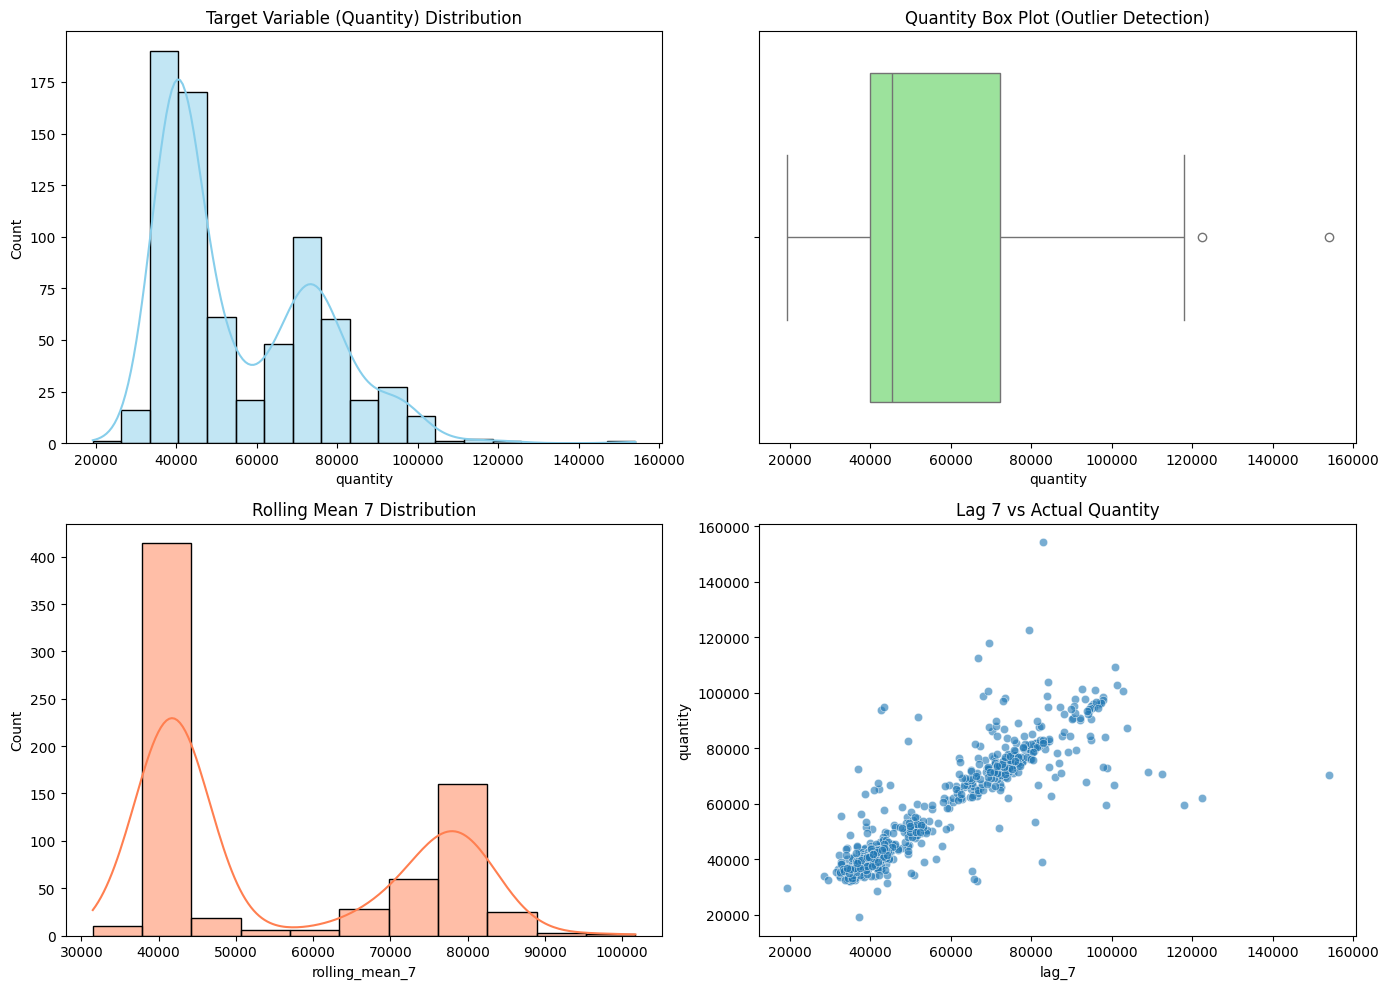

In [6]:
# --- 1. Load Data & Clean Timeline ---
df_raw = pd.read_csv('data/raw/sales.csv')
df_raw.columns = [c.lower().strip() for c in df_raw.columns]
df_raw['date'] = pd.to_datetime(df_raw['date'])

# Aggregate sales quantity per day
df_daily = df_raw.groupby('date')['quantity'].sum().reset_index()
df_daily = df_daily.sort_values('date').reset_index(drop=True)

# Ensure full daily timeline without missing date gaps
full_date_range = pd.date_range(start=df_daily['date'].min(), end=df_daily['date'].max(), freq='D')
df_daily = df_daily.set_index('date').reindex(full_date_range, fill_value=0).rename_axis('date').reset_index()

# --- 2. Build Features Pipeline ---
def build_daily_features(df, date_col='date', target_col='quantity'):
    df = df.copy()

    # Calendar features
    df['day_of_week'] = df[date_col].dt.dayofweek
    df['day_of_month'] = df[date_col].dt.day
    df['month'] = df[date_col].dt.month
    df['quarter'] = df[date_col].dt.quarter
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

    # Lag features
    for lag in [1, 7, 14, 28]:
        df[f'lag_{lag}'] = df[target_col].shift(lag)

    # Rolling window stats
    df['rolling_mean_7'] = df[target_col].shift(1).rolling(window=7).mean()
    df['rolling_std_7'] = df[target_col].shift(1).rolling(window=7).std()
    df['rolling_mean_28'] = df[target_col].shift(1).rolling(window=28).mean()

    return df.dropna().reset_index(drop=True)

# Create df_featured
df_featured = build_daily_features(df_daily)
print(f"✅ df_featured successfully defined! Dataset shape: {df_featured.shape}\n")

# --- 3. Compute Summary Statistics Table ---
def compute_feature_summary(df):
    num_cols = df.select_dtypes(include=[np.number]).columns

    summary = []
    for col in num_cols:
        col_data = df[col].dropna()
        summary.append({
            'Feature': col,
            'Mean': round(col_data.mean(), 2),
            'Std Dev': round(col_data.std(), 2),
            'Median (Q2)': round(col_data.median(), 2),
            'IQR': round(col_data.quantile(0.75) - col_data.quantile(0.25), 2),
            'Min': round(col_data.min(), 2),
            'Max': round(col_data.max(), 2),
            'Skewness': round(col_data.skew(), 2),
            'Zero Count': (col_data == 0).sum()
        })

    return pd.DataFrame(summary)

summary_df = compute_feature_summary(df_featured)
print("=== FEATURE DISTRIBUTION SUMMARY ===")
display(summary_df)

# --- 4. Plot Distributions ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df_featured['quantity'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Target Variable (Quantity) Distribution')

sns.boxplot(x=df_featured['quantity'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Quantity Box Plot (Outlier Detection)')

sns.histplot(df_featured['rolling_mean_7'], kde=True, ax=axes[1, 0], color='coral')
axes[1, 0].set_title('Rolling Mean 7 Distribution')

sns.scatterplot(x=df_featured['lag_7'], y=df_featured['quantity'], ax=axes[1, 1], alpha=0.6)
axes[1, 1].set_title('Lag 7 vs Actual Quantity')

plt.tight_layout()
plt.show()

In [ ]:
# 1. Load sales.csv
print("Loading sales.csv...")
df_raw = pd.read_csv('data/raw/sales.csv')

# Clean column names
df_raw.columns = [c.lower().strip() for c in df_raw.columns]

# Define key columns
date_col = 'date'
target_col = 'quantity' # Choose 'quantity' for sales volume or 'sum_total' for sales revenue

print(f"✅ Date Column: '{date_col}' | Target Column: '{target_col}'")

# Convert date
df_raw[date_col] = pd.to_datetime(df_raw[date_col])

# 2. Aggregate Daily Sales Total
print("\nAggregating total sales by date...")
df_daily = df_raw.groupby(date_col)[target_col].sum().reset_index()
df_daily = df_daily.sort_values(date_col).reset_index(drop=True)

# 3. Time-Series Feature Engineering
def build_daily_features(df, date_col, target_col):
    df = df.copy()

    # Calendar features
    df['day_of_week'] = df[date_col].dt.dayofweek
    df['day_of_month'] = df[date_col].dt.day
    df['month'] = df[date_col].dt.month
    df['quarter'] = df[date_col].dt.quarter
    df['year'] = df[date_col].dt.year
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

    # Lag features (Sales 1 day, 7 days, 14 days, and 28 days ago)
    for lag in [1, 7, 14, 28]:
        df[f'lag_{lag}'] = df[target_col].shift(lag)

    # Rolling window statistics (7-day and 28-day moving average / std)
    df['rolling_mean_7'] = df[target_col].shift(1).rolling(window=7).mean()
    df['rolling_std_7'] = df[target_col].shift(1).rolling(window=7).std()
    df['rolling_mean_28'] = df[target_col].shift(1).rolling(window=28).mean()

    return df.dropna().reset_index(drop=True)

df_featured = build_daily_features(df_daily, date_col, target_col)

print(f"\n🎉 Feature Engineering Complete!")
print(f"Engineered Daily Sales Shape: {df_featured.shape}")
df_featured.head(5)

Loading sales.csv...
✅ Date Column: 'date' | Target Column: 'quantity'

Aggregating total sales by date...

🎉 Feature Engineering Complete!
Engineered Daily Sales Shape: (733, 15)


,date,quantity,day_of_week,day_of_month,month,quarter,year,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_28
0,2022-09-25,32190.126,6,25,9,3,2022,1,41013.667,34790.623,34412.473,35616.579,41812.132000,4781.285251,42079.467179
1,2022-09-26,36181.587,0,26,9,3,2022,0,32190.126,42762.197,39954.473,41935.293,41440.632429,5469.300065,41957.093857
2,2022-09-27,40781.135,1,27,9,3,2022,0,36181.587,40465.878,41642.076,40996.841,40500.545286,5762.003966,41751.604357
3,2022-09-28,38544.177,2,28,9,3,2022,0,40781.135,40511.620,41050.960,43387.136,40545.582000,5762.919817,41743.900571
4,2022-09-29,44126.543,3,29,9,3,2022,0,38544.177,42238.317,44708.170,50626.987,40264.518714,5812.615037,41570.937750


Train Period: 2022-09-25 to 2024-08-27 (703 days)
Val Period:   2024-08-28 to 2024-09-26 (30 days)

=== MODEL PERFORMANCE COMPARISON ===


,Model,MAE,RMSE
0,Naive Lag-7 Baseline,3607.3352,4929.728348
1,Random Forest Regressor,4028.4134,5277.068432


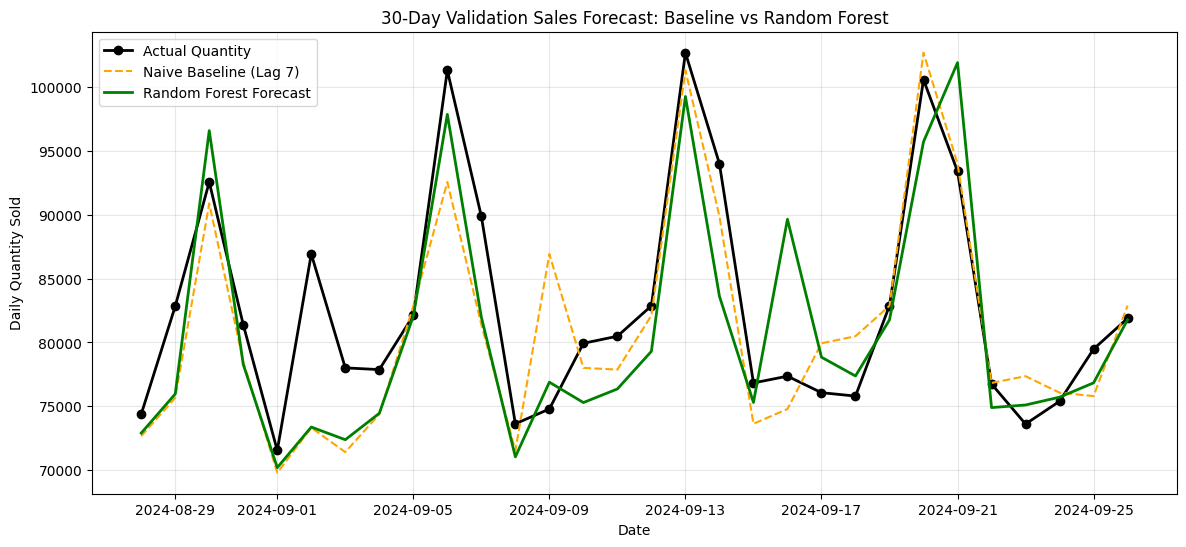

In [7]:
# --- 1. Time-Based Train / Validation Split ---
VAL_DAYS = 30  # Forecast the last 30 days

train_df = df_featured.iloc[:-VAL_DAYS].copy()
val_df = df_featured.iloc[-VAL_DAYS:].copy()

print(f"Train Period: {train_df['date'].min().strftime('%Y-%m-%d')} to {train_df['date'].max().strftime('%Y-%m-%d')} ({len(train_df)} days)")
print(f"Val Period:   {val_df['date'].min().strftime('%Y-%m-%d')} to {val_df['date'].max().strftime('%Y-%m-%d')} ({len(val_df)} days)")

# Select features (exclude date and target column)
feature_cols = [c for c in df_featured.columns if c not in ['date', 'quantity']]

X_train, y_train = train_df[feature_cols], train_df['quantity']
X_val, y_val = val_df[feature_cols], val_df['quantity']

# --- 2. Baseline Model (Naive Lag-7 Predictor) ---
y_pred_baseline = val_df['lag_7']

# --- 3. Random Forest Regressor ---
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_val)

# --- 4. Evaluate Models (MAE & RMSE) ---
metrics = {
    'Model': ['Naive Lag-7 Baseline', 'Random Forest Regressor'],
    'MAE': [
        mean_absolute_error(y_val, y_pred_baseline),
        mean_absolute_error(y_val, y_pred_rf)
    ],
    'RMSE': [
        root_mean_squared_error(y_val, y_pred_baseline),
        root_mean_squared_error(y_val, y_pred_rf)
    ]
}

eval_df = pd.DataFrame(metrics)
print("\n=== MODEL PERFORMANCE COMPARISON ===")
display(eval_df)

# --- 5. Plot Actual vs Forecasted Sales ---
plt.figure(figsize=(14, 6))
plt.plot(val_df['date'], y_val.values, label='Actual Quantity', color='black', linewidth=2, marker='o')
plt.plot(val_df['date'], y_pred_baseline.values, label='Naive Baseline (Lag 7)', color='orange', linestyle='--')
plt.plot(val_df['date'], y_pred_rf, label='Random Forest Forecast', color='green', linewidth=2)

plt.title('30-Day Validation Sales Forecast: Baseline vs Random Forest')
plt.xlabel('Date')
plt.ylabel('Daily Quantity Sold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

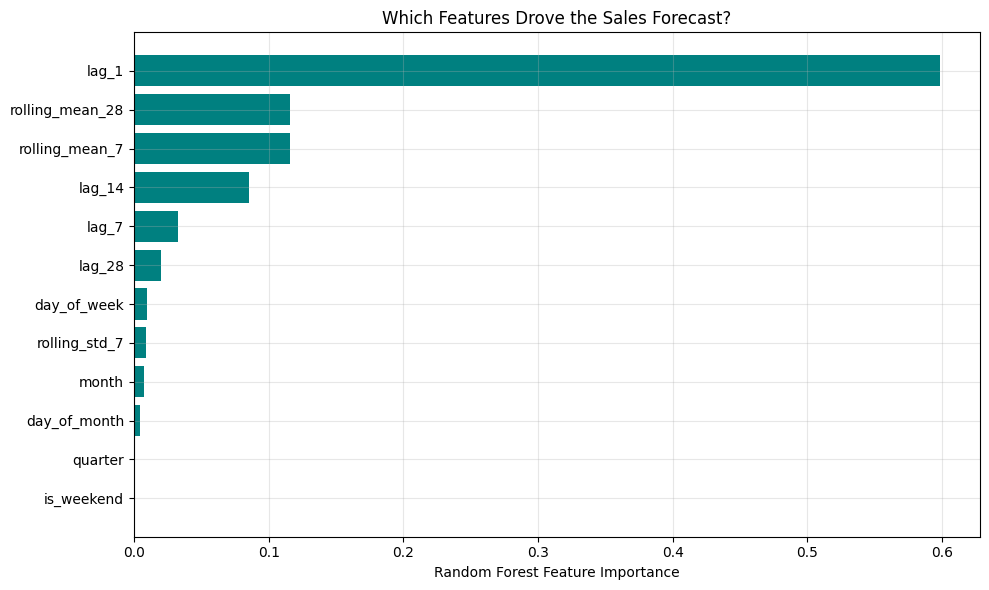

,Feature,Importance
5,lag_1,0.598262
11,rolling_mean_28,0.115962
9,rolling_mean_7,0.115679
7,lag_14,0.085139
6,lag_7,0.032938
8,lag_28,0.019768
0,day_of_week,0.009655
10,rolling_std_7,0.009204
2,month,0.007372
1,day_of_month,0.004375


In [8]:
# 1. Extract Feature Importances
importances = rf_model.feature_importances_
feature_names = X_train.columns

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# 2. Plot Feature Importances
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='teal')
plt.xlabel('Random Forest Feature Importance')
plt.title('Which Features Drove the Sales Forecast?')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(importance_df.sort_values(by='Importance', ascending=False))